# Exploration des résultats de priorisation des sujets Facebook

Ce notebook présente les principaux résultats obtenus après la collecte,
le nettoyage, la classification automatique des publications, le regroupement
sémantique en sujets et l'analyse des réactions dans les commentaires.

Les indicateurs présentés décrivent l'attention et les réactions observées
dans le corpus Facebook étudié.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Le notebook se trouve dans /notebooks,
# donc le dossier du projet est le dossier parent.
PROJECT_DIR = Path.cwd().parent

DATA_DIR = (
    PROJECT_DIR
    / "datasets"
    / "facebook"
    / "processed"
)

FILE = DATA_DIR / "Data_Topics_Priority_Indicators.xlsx"

print("Projet :", PROJECT_DIR)
print("Fichier :", FILE)
print("Existe :", FILE.exists())

Projet : c:\Users\ouedr\Desktop\memoire_priorisation
Fichier : c:\Users\ouedr\Desktop\memoire_priorisation\datasets\facebook\processed\Data_Topics_Priority_Indicators.xlsx
Existe : True


In [2]:
topics = pd.read_excel(FILE)

print("Nombre de sujets :", len(topics))
print("Nombre de colonnes :", len(topics.columns))

topics.head()

Nombre de sujets : 17
Nombre de colonnes : 34


,topicCluster,mainDomain,representativePostId,representativeText,numberOfPosts,collectedComments,usableComments,commentCoverageRate,discussionIntensity,reactionDocumentation,...,postsWithSharesData,sharesSumAvailable,sharesCoverageRate,postsWithPlatformCommentCount,platformCommentCountSumAvailable,platformCommentsCoverageRate,hasDiscussionSignal,hasSentimentSignal,hasLikesSignal,hasSharesSignal
0,TOPIC_010,SANTE,RECONSTRUCTED_003,"Troubles sexuels : Tabous, automédication et ...",1,20,17,0.850000,2.890372,PLUS_DOCUMENTEE,...,0,NaN,0.0,1,20,1,True,True,False,False
1,TOPIC_001,SCIENCE_TECHNOLOGIE_INNOVATION,1520308410137966,‎CONCOURS NATIONAL DE DÉTECTION DE TALENTS SCI...,2,22,15,0.681818,2.772589,PLUS_DOCUMENTEE,...,1,86.0,0.5,2,33,1,True,True,True,True
2,TOPIC_012,INFRASTRUCTURES_TRANSPORT,RECONSTRUCTED_005,Sécurité routière : L’ONASER traque les compor...,1,12,8,0.666667,2.197225,MODEREE,...,0,NaN,0.0,1,12,1,True,True,False,False
3,TOPIC_002,AGRICULTURE_ELEVAGE_ALIMENTATION,RECONSTRUCTED_007,"Burkina Faso : Aliou Diongue, un expert aguerr...",1,7,4,0.571429,1.609438,FAIBLE,...,0,NaN,0.0,1,7,1,True,True,False,False
4,TOPIC_004,ADMINISTRATION_GOUVERNANCE,RECONSTRUCTED_012,♦️Annonce | Le nouveau code général des collec...,2,4,3,0.750000,1.386294,FAIBLE,...,0,NaN,0.0,2,4,1,True,True,False,False


In [3]:
summary = pd.DataFrame({
    "Indicateur": [
        "Sujets détectés",
        "Publications pertinentes",
        "Commentaires collectés",
        "Commentaires analysés",
        "Sujets avec réactions exploitables",
        "Sujets sans réaction exploitable"
    ],
    "Valeur": [
        len(topics),
        int(topics["numberOfPosts"].sum()),
        int(topics["collectedComments"].sum()),
        int(topics["analyzedComments"].sum()),
        int(topics["hasDiscussionSignal"].sum()),
        int((~topics["hasDiscussionSignal"]).sum())
    ]
})

summary

,Indicateur,Valeur
0,Sujets détectés,17
1,Publications pertinentes,20
2,Commentaires collectés,82
3,Commentaires analysés,59
4,Sujets avec réactions exploitables,12
5,Sujets sans réaction exploitable,5


# Exploration des résultats de priorisation des sujets Facebook

Ce notebook présente les principaux résultats obtenus après la collecte,
le nettoyage, la classification automatique des publications, le regroupement
sémantique en sujets et l'analyse des réactions dans les commentaires.

Les indicateurs présentés décrivent l'attention et les réactions observées
dans le corpus Facebook étudié.

In [4]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Le notebook se trouve dans /notebooks,
# donc le dossier du projet est le dossier parent.
PROJECT_DIR = Path.cwd().parent

DATA_DIR = (
    PROJECT_DIR
    / "datasets"
    / "facebook"
    / "processed"
)

FILE = DATA_DIR / "Data_Topics_Priority_Indicators.xlsx"

print("Projet :", PROJECT_DIR)
print("Fichier :", FILE)
print("Existe :", FILE.exists())

Projet : c:\Users\ouedr\Desktop\memoire_priorisation
Fichier : c:\Users\ouedr\Desktop\memoire_priorisation\datasets\facebook\processed\Data_Topics_Priority_Indicators.xlsx
Existe : True


In [5]:
topics = pd.read_excel(FILE)

print("Nombre de sujets :", len(topics))
print("Nombre de colonnes :", len(topics.columns))

topics.head()

Nombre de sujets : 17
Nombre de colonnes : 34


,topicCluster,mainDomain,representativePostId,representativeText,numberOfPosts,collectedComments,usableComments,commentCoverageRate,discussionIntensity,reactionDocumentation,...,postsWithSharesData,sharesSumAvailable,sharesCoverageRate,postsWithPlatformCommentCount,platformCommentCountSumAvailable,platformCommentsCoverageRate,hasDiscussionSignal,hasSentimentSignal,hasLikesSignal,hasSharesSignal
0,TOPIC_010,SANTE,RECONSTRUCTED_003,"Troubles sexuels : Tabous, automédication et ...",1,20,17,0.850000,2.890372,PLUS_DOCUMENTEE,...,0,NaN,0.0,1,20,1,True,True,False,False
1,TOPIC_001,SCIENCE_TECHNOLOGIE_INNOVATION,1520308410137966,‎CONCOURS NATIONAL DE DÉTECTION DE TALENTS SCI...,2,22,15,0.681818,2.772589,PLUS_DOCUMENTEE,...,1,86.0,0.5,2,33,1,True,True,True,True
2,TOPIC_012,INFRASTRUCTURES_TRANSPORT,RECONSTRUCTED_005,Sécurité routière : L’ONASER traque les compor...,1,12,8,0.666667,2.197225,MODEREE,...,0,NaN,0.0,1,12,1,True,True,False,False
3,TOPIC_002,AGRICULTURE_ELEVAGE_ALIMENTATION,RECONSTRUCTED_007,"Burkina Faso : Aliou Diongue, un expert aguerr...",1,7,4,0.571429,1.609438,FAIBLE,...,0,NaN,0.0,1,7,1,True,True,False,False
4,TOPIC_004,ADMINISTRATION_GOUVERNANCE,RECONSTRUCTED_012,♦️Annonce | Le nouveau code général des collec...,2,4,3,0.750000,1.386294,FAIBLE,...,0,NaN,0.0,2,4,1,True,True,False,False


In [6]:
summary = pd.DataFrame({
    "Indicateur": [
        "Sujets détectés",
        "Publications pertinentes",
        "Commentaires collectés",
        "Commentaires analysés",
        "Sujets avec réactions exploitables",
        "Sujets sans réaction exploitable"
    ],
    "Valeur": [
        len(topics),
        int(topics["numberOfPosts"].sum()),
        int(topics["collectedComments"].sum()),
        int(topics["analyzedComments"].sum()),
        int(topics["hasDiscussionSignal"].sum()),
        int((~topics["hasDiscussionSignal"]).sum())
    ]
})

summary

,Indicateur,Valeur
0,Sujets détectés,17
1,Publications pertinentes,20
2,Commentaires collectés,82
3,Commentaires analysés,59
4,Sujets avec réactions exploitables,12
5,Sujets sans réaction exploitable,5


## Répartition des sujets par domaine

Cette analyse présente le nombre de sujets détectés dans chaque domaine.
Elle permet de caractériser la composition thématique du corpus retenu après
la classification automatique et le regroupement sémantique.

In [7]:
domain_counts = (
    topics["mainDomain"]
    .value_counts()
    .sort_values(ascending=True)
)

domain_counts

mainDomain
ENVIRONNEMENT_ENERGIE                    1
COOPERATION_RELATIONS_INTERNATIONALES    1
INFRASTRUCTURES_TRANSPORT                1
SANTE                                    2
SCIENCE_TECHNOLOGIE_INNOVATION           2
EDUCATION_FORMATION                      2
AGRICULTURE_ELEVAGE_ALIMENTATION         3
ADMINISTRATION_GOUVERNANCE               5
Name: count, dtype: int64

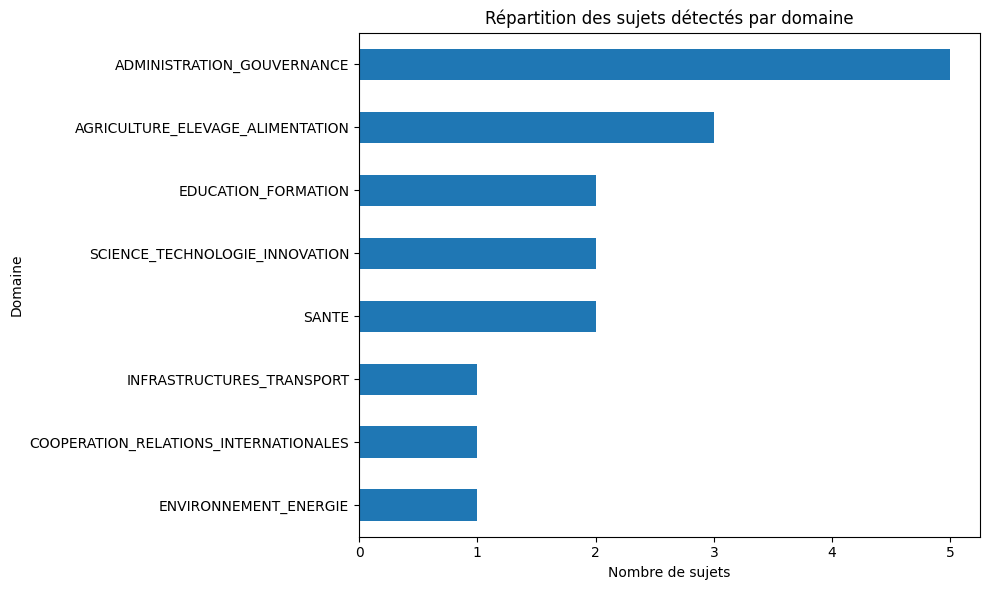

In [8]:
plt.figure(figsize=(10, 6))

domain_counts.plot(kind="barh")

plt.title("Répartition des sujets détectés par domaine")
plt.xlabel("Nombre de sujets")
plt.ylabel("Domaine")

plt.tight_layout()
plt.show()

## Attention observée autour des sujets

Le nombre de commentaires exploitables constitue un indicateur du niveau
de discussion observé autour de chaque sujet dans le corpus Facebook.

Il ne représente ni l'importance intrinsèque du sujet ni l'opinion de
l'ensemble de la population.

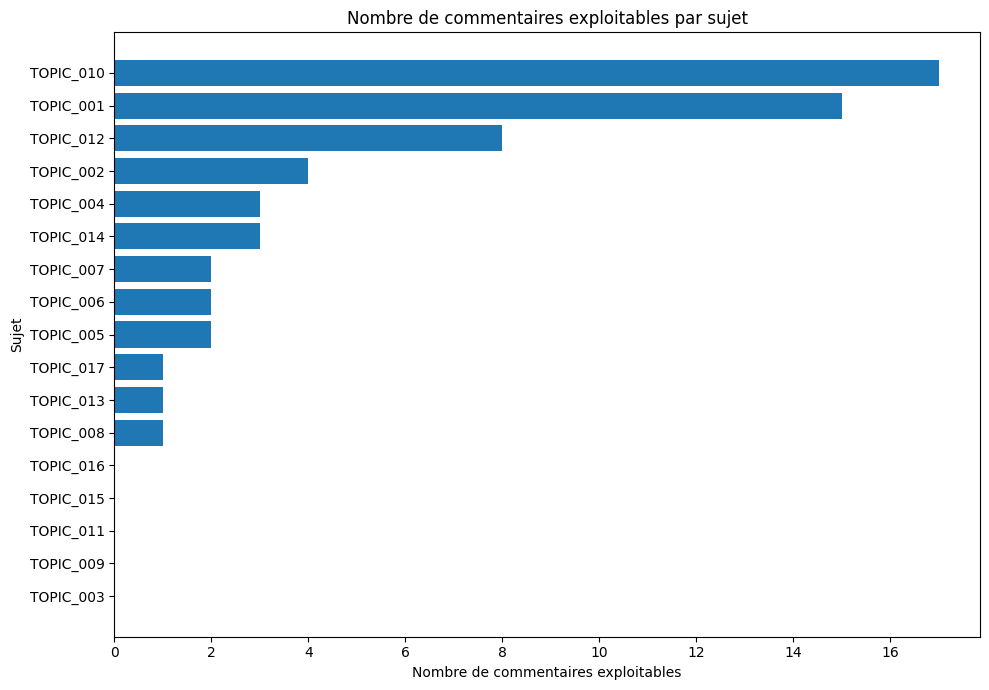

In [9]:
discussion = (
    topics[
        [
            "topicCluster",
            "usableComments"
        ]
    ]
    .sort_values(
        "usableComments",
        ascending=True
    )
)

plt.figure(figsize=(10, 7))

plt.barh(
    discussion["topicCluster"],
    discussion["usableComments"]
)

plt.title(
    "Nombre de commentaires exploitables par sujet"
)
plt.xlabel(
    "Nombre de commentaires exploitables"
)
plt.ylabel(
    "Sujet"
)

plt.tight_layout()
plt.show()

## Tonalité des commentaires analysés

La tonalité des commentaires est estimée automatiquement à l'aide d'un
modèle multilingue de classification de sentiment.

Les résultats doivent être interprétés comme une caractérisation du corpus
analysé et non comme une mesure représentative de l'opinion publique.

In [10]:
sentiment_global = pd.Series({
    "Positif": int(topics["positiveComments"].sum()),
    "Neutre": int(topics["neutralComments"].sum()),
    "Négatif": int(topics["negativeComments"].sum())
})

sentiment_global

Positif    36
Neutre     10
Négatif    13
dtype: int64

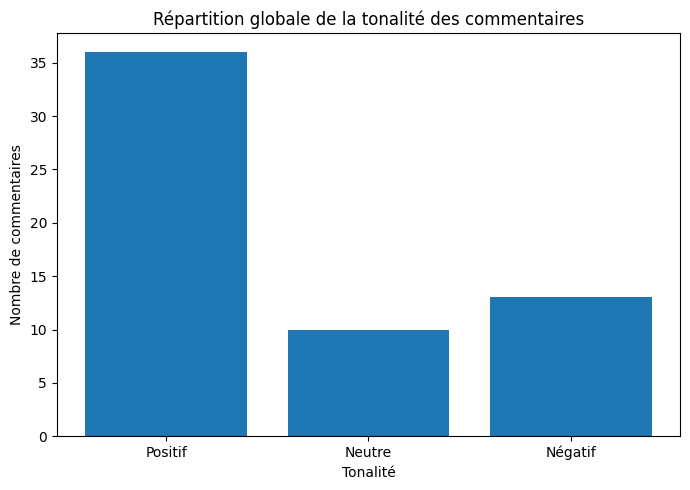

In [11]:
plt.figure(figsize=(7, 5))

plt.bar(
    sentiment_global.index,
    sentiment_global.values
)

plt.title(
    "Répartition globale de la tonalité des commentaires"
)
plt.ylabel(
    "Nombre de commentaires"
)
plt.xlabel(
    "Tonalité"
)

plt.tight_layout()
plt.show()

## Libellés descriptifs des sujets

Les identifiants techniques (`TOPIC_001`, `TOPIC_002`, etc.) sont utiles
pour assurer la traçabilité du traitement, mais ils sont peu lisibles dans
les graphiques.

Des libellés descriptifs courts sont donc dérivés du texte représentatif
de chaque sujet afin de faciliter l'interprétation des résultats.

In [12]:
import re

def create_topic_label(text, max_words=10):
    if pd.isna(text):
        return "Sujet non renseigné"

    text = str(text)

    # Suppression des URL
    text = re.sub(r"https?://\S+", "", text)

    # Normalisation des espaces
    text = re.sub(r"\s+", " ", text).strip()

    # On privilégie le début du texte représentatif
    words = text.split()

    if len(words) > max_words:
        label = " ".join(words[:max_words]) + "…"
    else:
        label = " ".join(words)

    return label


topics["topicLabelAuto"] = (
    topics["representativeText"]
    .apply(create_topic_label)
)

topics[
    [
        "topicCluster",
        "mainDomain",
        "topicLabelAuto"
    ]
]

,topicCluster,mainDomain,topicLabelAuto
0,TOPIC_010,SANTE,"Troubles sexuels : Tabous, automédication et r..."
1,TOPIC_001,SCIENCE_TECHNOLOGIE_INNOVATION,‎CONCOURS NATIONAL DE DÉTECTION DE TALENTS SCI...
2,TOPIC_012,INFRASTRUCTURES_TRANSPORT,Sécurité routière : L’ONASER traque les compor...
3,TOPIC_002,AGRICULTURE_ELEVAGE_ALIMENTATION,"Burkina Faso : Aliou Diongue, un expert aguerr..."
4,TOPIC_004,ADMINISTRATION_GOUVERNANCE,♦️Annonce | Le nouveau code général des collec...
5,TOPIC_014,AGRICULTURE_ELEVAGE_ALIMENTATION,Résultats provisoires de l’avis d’appel d’offr...
6,TOPIC_007,AGRICULTURE_ELEVAGE_ALIMENTATION,Lutte contre le vol de bétail : Le Burkina Faso…
7,TOPIC_005,EDUCATION_FORMATION,Sakoula : Une association offre des kits scola...
8,TOPIC_006,ENVIRONNEMENT_ENERGIE,Burkina Faso : Des chercheurs identifient les ...
9,TOPIC_017,SANTE,Recherche scientifique et souveraineté sanitai...


In [13]:
topic_dictionary = (
    topics[
        [
            "topicCluster",
            "mainDomain",
            "topicLabelAuto",
            "numberOfPosts",
            "usableComments"
        ]
    ]
    .sort_values("topicCluster")
    .reset_index(drop=True)
)

topic_dictionary

,topicCluster,mainDomain,topicLabelAuto,numberOfPosts,usableComments
0,TOPIC_001,SCIENCE_TECHNOLOGIE_INNOVATION,‎CONCOURS NATIONAL DE DÉTECTION DE TALENTS SCI...,2,15
1,TOPIC_002,AGRICULTURE_ELEVAGE_ALIMENTATION,"Burkina Faso : Aliou Diongue, un expert aguerr...",1,4
2,TOPIC_003,ADMINISTRATION_GOUVERNANCE,Grande finale de la première édition de la Cou...,2,0
3,TOPIC_004,ADMINISTRATION_GOUVERNANCE,♦️Annonce | Le nouveau code général des collec...,2,3
4,TOPIC_005,EDUCATION_FORMATION,Sakoula : Une association offre des kits scola...,1,2
5,TOPIC_006,ENVIRONNEMENT_ENERGIE,Burkina Faso : Des chercheurs identifient les ...,1,2
6,TOPIC_007,AGRICULTURE_ELEVAGE_ALIMENTATION,Lutte contre le vol de bétail : Le Burkina Faso…,1,2
7,TOPIC_008,COOPERATION_RELATIONS_INTERNATIONALES,Coopération Burkina–Chine : Un colloque pour t...,1,1
8,TOPIC_009,EDUCATION_FORMATION,MODERNISATION DES INFRASTRUCTURES ACADÉMIQUES ...,1,0
9,TOPIC_010,SANTE,"Troubles sexuels : Tabous, automédication et r...",1,17


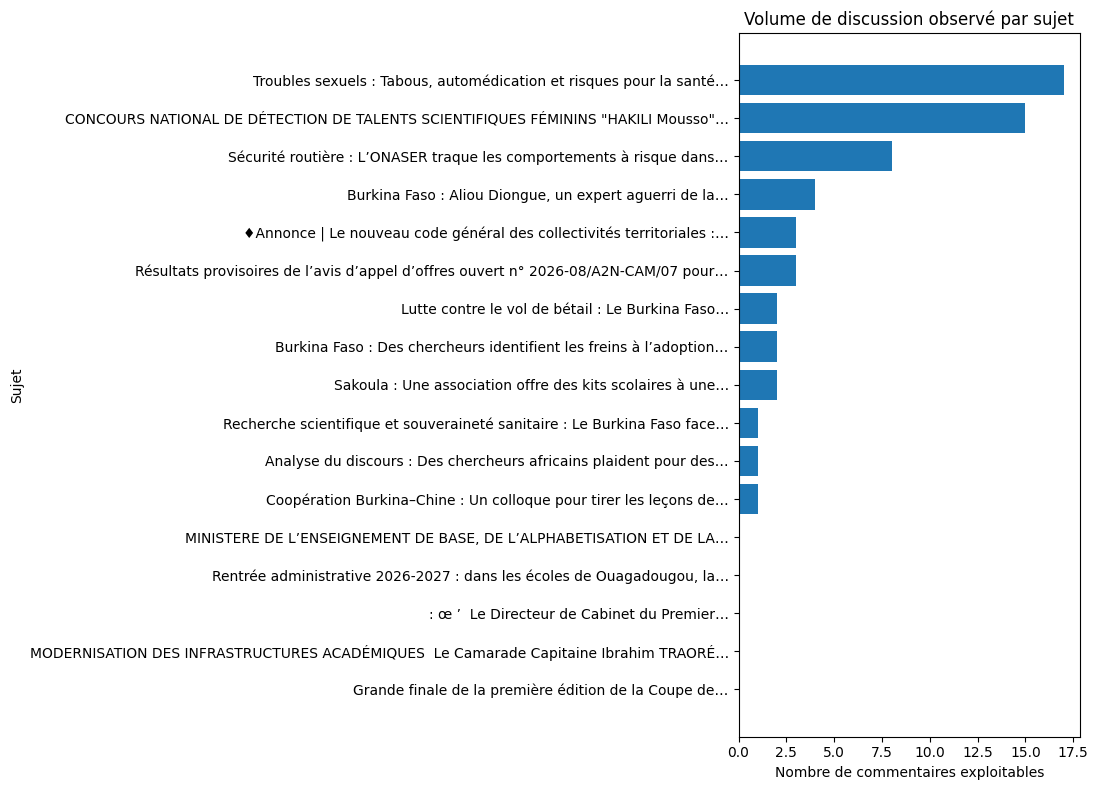

In [14]:
discussion_labels = (
    topics[
        [
            "topicLabelAuto",
            "usableComments"
        ]
    ]
    .sort_values(
        "usableComments",
        ascending=True
    )
)

plt.figure(figsize=(11, 8))

plt.barh(
    discussion_labels["topicLabelAuto"],
    discussion_labels["usableComments"]
)

plt.title(
    "Volume de discussion observé par sujet"
)

plt.xlabel(
    "Nombre de commentaires exploitables"
)

plt.ylabel(
    "Sujet"
)

plt.tight_layout()
plt.show()

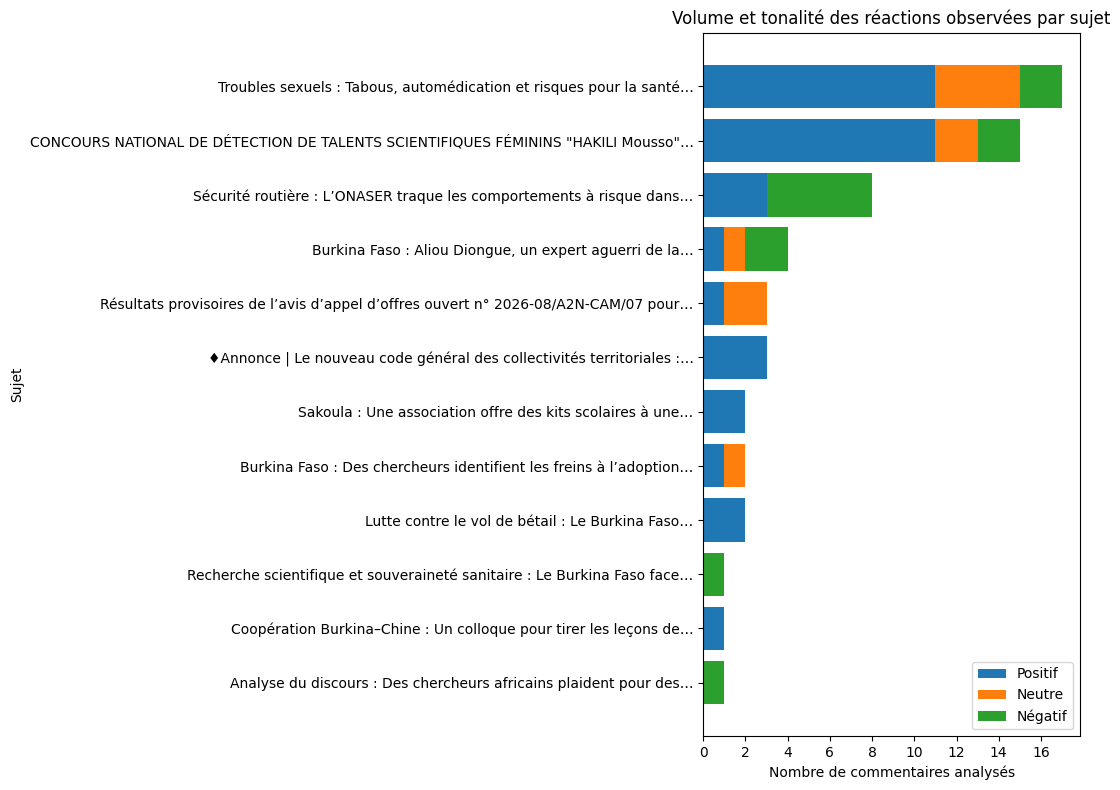

In [15]:
sentiment_topics = topics[
    topics["analyzedComments"] > 0
].copy()

sentiment_topics = sentiment_topics.sort_values(
    "analyzedComments",
    ascending=True
)

plt.figure(figsize=(11, 8))

plt.barh(
    sentiment_topics["topicLabelAuto"],
    sentiment_topics["positiveComments"],
    label="Positif"
)

plt.barh(
    sentiment_topics["topicLabelAuto"],
    sentiment_topics["neutralComments"],
    left=sentiment_topics["positiveComments"],
    label="Neutre"
)

plt.barh(
    sentiment_topics["topicLabelAuto"],
    sentiment_topics["negativeComments"],
    left=(
        sentiment_topics["positiveComments"]
        + sentiment_topics["neutralComments"]
    ),
    label="Négatif"
)

plt.title(
    "Volume et tonalité des réactions observées par sujet"
)

plt.xlabel(
    "Nombre de commentaires analysés"
)

plt.ylabel(
    "Sujet"
)

plt.legend()

plt.tight_layout()
plt.show()

## Tableau synthétique des sujets détectés

Le tableau suivant synthétise, pour chaque sujet, son domaine thématique,
le nombre de publications associées, le volume de commentaires analysés
et la répartition de leur tonalité.

Ces indicateurs caractérisent les réactions observées dans le corpus Facebook.
Ils constituent des signaux descriptifs et ne représentent pas, à eux seuls,
une décision de priorité gouvernementale.

In [17]:
final_table = topics[
    [
        "topicCluster",
        "topicLabelAuto",
        "mainDomain",
        "numberOfPosts",
        "collectedComments",
        "analyzedComments",
        "positiveRate",
        "neutralRate",
        "negativeRate",
        "meanSentiment",
        "reactionDocumentation"
    ]
].copy()


# Conversion des proportions en pourcentages
for col in [
    "positiveRate",
    "neutralRate",
    "negativeRate"
]:
    final_table[col] = (
        final_table[col] * 100
    ).round(1)


# Renommage pour une présentation plus lisible
final_table = final_table.rename(
    columns={
        "topicCluster": "ID sujet",
        "topicLabelAuto": "Sujet",
        "mainDomain": "Domaine",
        "numberOfPosts": "Publications",
        "collectedComments": "Commentaires collectés",
        "analyzedComments": "Commentaires analysés",
        "positiveRate": "% positif",
        "neutralRate": "% neutre",
        "negativeRate": "% négatif",
        "meanSentiment": "Sentiment moyen",
        "reactionDocumentation": "Documentation"
    }
)


final_table["Sentiment moyen"] = (
    final_table["Sentiment moyen"]
    .round(3)
)

final_table

,ID sujet,Sujet,Domaine,Publications,Commentaires collectés,Commentaires analysés,% positif,% neutre,% négatif,Sentiment moyen,Documentation
0,TOPIC_010,"Troubles sexuels : Tabous, automédication et r...",SANTE,1,20,17,64.7,23.5,11.8,0.529,PLUS_DOCUMENTEE
1,TOPIC_001,‎CONCOURS NATIONAL DE DÉTECTION DE TALENTS SCI...,SCIENCE_TECHNOLOGIE_INNOVATION,2,22,15,73.3,13.3,13.3,0.600,PLUS_DOCUMENTEE
2,TOPIC_012,Sécurité routière : L’ONASER traque les compor...,INFRASTRUCTURES_TRANSPORT,1,12,8,37.5,0.0,62.5,-0.250,MODEREE
3,TOPIC_002,"Burkina Faso : Aliou Diongue, un expert aguerr...",AGRICULTURE_ELEVAGE_ALIMENTATION,1,7,4,25.0,25.0,50.0,-0.250,FAIBLE
4,TOPIC_004,♦️Annonce | Le nouveau code général des collec...,ADMINISTRATION_GOUVERNANCE,2,4,3,100.0,0.0,0.0,1.000,FAIBLE
5,TOPIC_014,Résultats provisoires de l’avis d’appel d’offr...,AGRICULTURE_ELEVAGE_ALIMENTATION,1,4,3,33.3,66.7,0.0,0.333,FAIBLE
6,TOPIC_007,Lutte contre le vol de bétail : Le Burkina Faso…,AGRICULTURE_ELEVAGE_ALIMENTATION,1,3,2,100.0,0.0,0.0,1.000,TRES_FAIBLE
7,TOPIC_005,Sakoula : Une association offre des kits scola...,EDUCATION_FORMATION,1,2,2,100.0,0.0,0.0,1.000,TRES_FAIBLE
8,TOPIC_006,Burkina Faso : Des chercheurs identifient les ...,ENVIRONNEMENT_ENERGIE,1,2,2,50.0,50.0,0.0,0.500,TRES_FAIBLE
9,TOPIC_017,Recherche scientifique et souveraineté sanitai...,SANTE,1,3,1,0.0,0.0,100.0,-1.000,TRES_FAIBLE


In [18]:
OUTPUT_TABLE = (
    DATA_DIR
    / "Tableau_Synthetique_Sujets.xlsx"
)

final_table.to_excel(
    OUTPUT_TABLE,
    index=False
)

print("Tableau enregistré :")
print(OUTPUT_TABLE)

Tableau enregistré :
c:\Users\ouedr\Desktop\memoire_priorisation\datasets\facebook\processed\Tableau_Synthetique_Sujets.xlsx
